**MODELO XGBOOST - DATASET 0.2%**
Inspección de Botellas de 600ml (Llenado y Etiqueta)

In [1]:
# 1. Instalación de librerías
!pip install xgboost -q

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import xgboost as xgb
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import (
    confusion_matrix, classification_report, roc_auc_score,
    roc_curve, precision_recall_curve, f1_score, accuracy_score,
    precision_score, recall_score
)

In [2]:
# 2. Carga del Dataset
from google.colab import files
uploaded = files.upload()

filename = 'dataset_inspeccion_0_2_limpio.csv'
df = pd.read_csv(filename)

print("Dimensiones del dataset 0.2%:", df.shape)
print(df.head())

Saving dataset_inspeccion_0_2_limpio.csv to dataset_inspeccion_0_2_limpio (1).csv
Dimensiones del dataset 0.2%: (5000, 6)
   bottle_id  fill_level_ml label_present    status  label_present_num  target
0  BOT_01502         598.35            SI  ACEPTADO                  1       0
1  BOT_02587         596.04            SI  ACEPTADO                  1       0
2  BOT_02654         603.09            SI  ACEPTADO                  1       0
3  BOT_01056         597.99            SI  ACEPTADO                  1       0
4  BOT_00706         601.82            SI  ACEPTADO                  1       0


In [3]:
# 3. Preparación de Datos y Manejo de Desbalance
X = df[['fill_level_ml', 'label_present_num']]
y = df['target']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

# Ponderación para clases desbalanceadas (0.5% rechazos)
neg_count = (y_train == 0).sum()
pos_count = (y_train == 1).sum()
scale_pos_weight = neg_count / pos_count if pos_count > 0 else 1.0

In [4]:
# 4. Entrenamiento del Modelo XGBoost
model = xgb.XGBClassifier(
    scale_pos_weight=scale_pos_weight,
    random_state=42,
    eval_metric='logloss',
    n_estimators=100,
    learning_rate=0.1
)
model.fit(X_train, y_train)

y_pred_base = model.predict(X_test)
y_pred_proba = model.predict_proba(X_test)[:, 1]

print("\n--- INFORME DE CLASIFICACIÓN (Umbral Estándar 0.5) ---")
print(classification_report(y_test, y_pred_base))


--- INFORME DE CLASIFICACIÓN (Umbral Estándar 0.5) ---
              precision    recall  f1-score   support

           0       1.00      0.99      1.00       998
           1       0.20      1.00      0.33         2

    accuracy                           0.99      1000
   macro avg       0.60      1.00      0.66      1000
weighted avg       1.00      0.99      0.99      1000



**Métricas de evaluación**

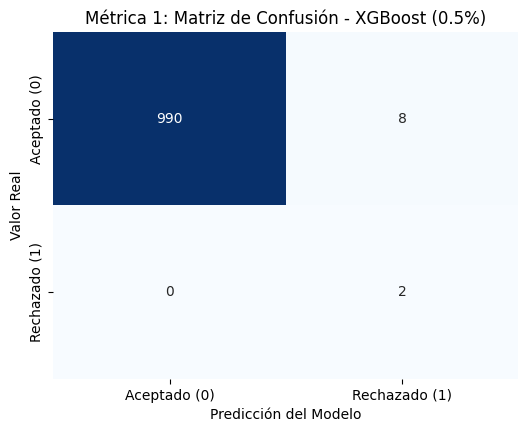

In [5]:
# 1. Matriz de Confusión
plt.figure(figsize=(6, 45/10))
cm = confusion_matrix(y_test, y_pred_base)
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', cbar=False,
            xticklabels=['Aceptado (0)', 'Rechazado (1)'],
            yticklabels=['Aceptado (0)', 'Rechazado (1)'])
plt.title('Métrica 1: Matriz de Confusión - XGBoost (0.5%)')
plt.xlabel('Predicción del Modelo')
plt.ylabel('Valor Real')
plt.show()

In [6]:
# 2. Ajuste de Umbral (Threshold Tuning basado en F1-Score)
precisions, recalls, thresholds = precision_recall_curve(y_test, y_pred_proba)
f1_scores = 2 * (precisions * recalls) / (precisions + recalls + 1e-10)
best_idx = np.argmax(f1_scores)
best_threshold = thresholds[best_idx] if best_idx < len(thresholds) else 0.5

print(f"\nMétrica 2: Mejor umbral optimizado: {best_threshold:.4f} (F1-Score máximo: {f1_scores[best_idx]:.4f})")
y_pred_opt = (y_pred_proba >= best_threshold).astype(int)

print("Matriz de Confusión con Umbral Ajustado:")
print(confusion_matrix(y_test, y_pred_opt))


Métrica 2: Mejor umbral optimizado: 0.9991 (F1-Score máximo: 1.0000)
Matriz de Confusión con Umbral Ajustado:
[[998   0]
 [  0   2]]


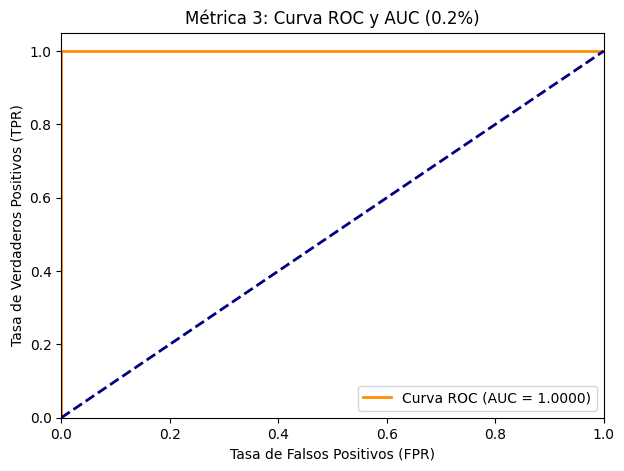

In [8]:
# 3. Curva ROC y AUC
auc_score = roc_auc_score(y_test, y_pred_proba)
fpr, tpr, _ = roc_curve(y_test, y_pred_proba)

plt.figure(figsize=(7, 5))
plt.plot(fpr, tpr, color='darkorange', lw=2, label=f'Curva ROC (AUC = {auc_score:.4f})')
plt.plot([0, 1], [0, 1], color='navy', lw=2, linestyle='--')
plt.xlim([0.0, 1.0])
plt.ylim([0.0, 1.05])
plt.xlabel('Tasa de Falsos Positivos (FPR)')
plt.ylabel('Tasa de Verdaderos Positivos (TPR)')
plt.title('Métrica 3: Curva ROC y AUC (0.2%)')
plt.legend(loc="lower right")
plt.show()

In [9]:
# 4. Validación Cruzada (Stratified K-Fold)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_scores = cross_val_score(model, X, y, cv=cv, scoring='roc_auc')
print(f"\nMétrica 4: Validación Cruzada ROC-AUC (5-Fold): {cv_scores.mean():.4f} (+/- {cv_scores.std():.4f})")


Métrica 4: Validación Cruzada ROC-AUC (5-Fold): 0.9977 (+/- 0.0026)


In [10]:
# 5. A/B Testing (Simulación de producción: Regla Tradicional vs XGBoost Optimizado)
def baseline_rule(row):
    # Especificación de calidad: Llenado 600ml +/- 2% [588 - 612] o etiqueta ausente
    if row['fill_level_ml'] < 588 or row['fill_level_ml'] > 612 or row['label_present_num'] == 0:
        return 1
    return 0

df_test = X_test.copy()
df_test['true'] = y_test.values
df_test['baseline_pred'] = df_test.apply(baseline_rule, axis=1)
df_test['xgb_pred'] = y_pred_opt

print("\n--- Métrica 5: Simulación de A/B Testing ---")
ab_results = pd.DataFrame({
    'Métrica': ['Accuracy', 'Precision', 'Recall'],
    'Baseline (Reglas)': [
        accuracy_score(df_test['true'], df_test['baseline_pred']),
        precision_score(df_test['true'], df_test['baseline_pred'], zero_division=0),
        recall_score(df_test['true'], df_test['baseline_pred'], zero_division=0)
    ],
    'XGBoost (Modelo IA)': [
        accuracy_score(df_test['true'], df_test['xgb_pred']),
        precision_score(df_test['true'], df_test['xgb_pred'], zero_division=0),
        recall_score(df_test['true'], df_test['xgb_pred'], zero_division=0)
    ]
})
print(ab_results.to_string(index=False))


--- Métrica 5: Simulación de A/B Testing ---
  Métrica  Baseline (Reglas)  XGBoost (Modelo IA)
 Accuracy                1.0                  1.0
Precision                1.0                  1.0
   Recall                1.0                  1.0


In [11]:
# 6. Comparativa vs Baseline (Detallada)
print("\n--- Métrica 6: Comparativa Directa vs Baseline ---")
f1_base = f1_score(df_test['true'], df_test['baseline_pred'], zero_division=0)
f1_xgb = f1_score(df_test['true'], df_test['xgb_pred'], zero_division=0)
print(f"F1-Score Baseline: {f1_base:.4f}")
print(f"F1-Score XGBoost (Optimizado): {f1_xgb:.4f}")


--- Métrica 6: Comparativa Directa vs Baseline ---
F1-Score Baseline: 1.0000
F1-Score XGBoost (Optimizado): 1.0000
